In [ ]:
from os import makedirs
!pip install pandas matplotlib seaborn

In [6]:
import json
import os
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [39]:

def load_data(jsonl_path: str) -> pd.DataFrame:
    """Loads the benchmark results from a .jsonl file into a pandas DataFrame."""
    records = []
    with open(jsonl_path, 'r') as f:
        for line in f:
            # Each line is a JSON object representing an EnrichedResult
            # We flatten the nested solver_result into the main record
            record = json.loads(line)
            solver_data = record.pop('solver_result')
            record.update(solver_data)
            records.append(record)

    df = pd.DataFrame(records)
    # --- Data Cleaning and Preparation ---
    # Convert numeric columns from strings where necessary
    df['iters'] = pd.to_numeric(df['iters'], errors='coerce') # 'N/A' becomes NaN

    # Create a total CPU time column
    df['total_cpu_time_s'] = df['cpu_user_time_s'] + df['cpu_system_time_s']

    return df

def plot_performance_bars(df: pd.DataFrame, output_dir: str):
    """
    Generates and saves bar charts comparing solver performance for each matrix.
    """
    if not os.path.exists(output_dir):
        os.makedirs(output_dir)

    # Get a list of unique matrices to generate a chart for each
    unique_matrices = df['matrix_name'].unique()

    for matrix in unique_matrices:
        print(f"📊 Generating performance chart for matrix: {matrix}...")

        # Filter the DataFrame for the current matrix
        matrix_df = df[df['matrix_name'] == matrix].sort_values('solver_name')

        # Create a figure with 3 subplots (for time, ram, and cpu)
        fig, axes = plt.subplots(1, 3, figsize=(20, 6), sharex=True)
        fig.suptitle(f'Performance Benchmark for Matrix: {matrix} (Size: {matrix_df.iloc[0]["matrix_size"]})', fontsize=16)

        # Plot 1: Runtime in Milliseconds
        sns.barplot(ax=axes[0], data=matrix_df, x='solver_name', y='time_ms', hue='solver_name', palette='viridis',legend=False)
        axes[0].set_title('Runtime (ms)')
        axes[0].set_ylabel('Time (ms)')
        axes[0].set_xlabel('')

        # Plot 2: Peak RAM in Megabytes
        matrix_df['max_ram_mb'] = matrix_df['max_ram_kb'] / 1024
        sns.barplot(ax=axes[1], data=matrix_df, x='solver_name', y='max_ram_mb',hue='solver_name', palette='plasma')
        axes[1].set_title('Peak RAM (MB)')
        axes[1].set_ylabel('Memory (MB)')
        axes[1].set_xlabel('Solver')

        # Plot 3: Total CPU Time
        sns.barplot(ax=axes[2], data=matrix_df, x='solver_name', y='total_cpu_time_s', hue='solver_name',palette='magma')
        axes[2].set_title('Total CPU Time (s)')
        axes[2].set_ylabel('Time (s)')
        axes[2].set_xlabel('')

        # Improve layout and save the figure
        plt.xticks(rotation=45, ha='right')
        plt.tight_layout(rect=[0, 0.03, 1, 0.95]) # Adjust layout to make room for suptitle

        output_path = os.path.join(output_dir, f"{matrix}_performance.png")
        plt.savefig(output_path, dpi=150)
        plt.show()
        plt.close(fig) # Close the figure to free up memory

In [54]:
df = load_data("./benchmark_symmetric.jsonl")

In [55]:
df

,config_file,cpu_user_time_s,cpu_system_time_s,max_ram_kb,solver_name,matrix_name,matrix_size,time_ms,iters,final_rel_res,total_cpu_time_s
0,test-all/bcsstm05_lu.json,0.54,0.00,5692,LU Decomposition,BCSSTM05,153,1,NaN,0.000000e+00,0.54
1,test-all/bcsstk10_lu.json,2.21,0.01,35192,LU Decomposition,BCSSTK10,1086,242,NaN,5.122964e-16,2.22
2,test-all/s3rmt3m1_lu.json,1882.03,1.28,554740,LU Decomposition,S3RMT3M1,5489,127075,NaN,2.401744e-15,1883.31
3,test-all/plat1919_gmres.json,8.13,0.03,62584,GMRES(100),PLAT1919,1919,455,100.0,3.287241e-03,8.16
4,test-all/bcsstk19_bicgstab.json,211.77,0.04,14816,BiCGSTAB,BCSSTK19,817,14332,1634.0,8.688816e-08,211.81
...,...,...,...,...,...,...,...,...,...,...,...
424,test-all/bcsstm01_gmres.json,0.13,0.00,6260,GMRES(100),BCSSTM01,48,0,100.0,1.797547e-16,0.13
425,test-all/bcsstk18_cg.json,4361.15,17.48,1236724,Conjugate Gradient,BCSSTK18,11948,317659,NaN,5.390534e-08,4378.63
426,test-all/bcsstk24_bicgstab.json,827.24,3.64,134840,BiCGSTAB,BCSSTK24,3562,61123,7124.0,2.623342e-08,830.88
427,test-all/bcsstm08_bicgstab.json,20.10,0.06,19244,BiCGSTAB,BCSSTM08,1074,1436,152.0,3.892630e-09,20.16


In [56]:
plot_performance_bars(df, "./plots/plot_bar")

📊 Generating performance chart for matrix: BCSSTM05...
📊 Generating performance chart for matrix: BCSSTK10...
📊 Generating performance chart for matrix: S3RMT3M1...
📊 Generating performance chart for matrix: PLAT1919...
📊 Generating performance chart for matrix: BCSSTK19...
📊 Generating performance chart for matrix: BCSSTK14...
📊 Generating performance chart for matrix: BCSSTK07...
📊 Generating performance chart for matrix: BCSSTM09...
📊 Generating performance chart for matrix: DWT_878...
📊 Generating performance chart for matrix: BCSSTM12...
📊 Generating performance chart for matrix: DWT_992...
📊 Generating performance chart for matrix: S1RMQ4M1...
📊 Generating performance chart for matrix: BCSSTK18...
📊 Generating performance chart for matrix: BCSSTK03...
📊 Generating performance chart for matrix: BCSSTM27...
📊 Generating performance chart for matrix: BCSSTM22...
📊 Generating performance chart for matrix: DWT_245...
📊 Generating performance chart for matrix: BCSSTK28...
📊 Generating 

In [57]:

def plot_scalability_scatter(df: pd.DataFrame, output_dir: str):
    """
    Generates a scatter plot of runtime vs. matrix size, colored by solver.
    """
    print("📈 Generating scalability scatter plot...")
    plt.figure(figsize=(12, 8))

    ax = sns.scatterplot(
        data=df,
        x='matrix_size',
        y='time_ms',
        hue='solver_name',   # Color points by solver
        style='solver_name', # Use different marker shapes for each solver
        s=150,               # Set point size
        alpha=0.8,           # Set point transparency
        palette='bright'     # Use a color palette with good contrast
    )

    # Use a logarithmic scale for the y-axis (runtime) because LU is much slower
    ax.set_yscale('log')
    ax.set_xscale('log') # Log scale on x-axis can also help spread out matrix sizes

    ax.set_title('Solver Scalability: Runtime vs. Matrix Size', fontsize=16)
    ax.set_xlabel('Matrix Size (n x n) - Log Scale', fontsize=12)
    ax.set_ylabel('Runtime (ms) - Log Scale', fontsize=12)
    ax.grid(True, which="both", ls="--")
    ax.legend(title='Solver')

    output_path = os.path.join(output_dir, "solver_scalability_scatter.png")
    plt.savefig(output_path, dpi=150)
    plt.show(block=False)
    plt.close()

📈 Generating scalability scatter plot...


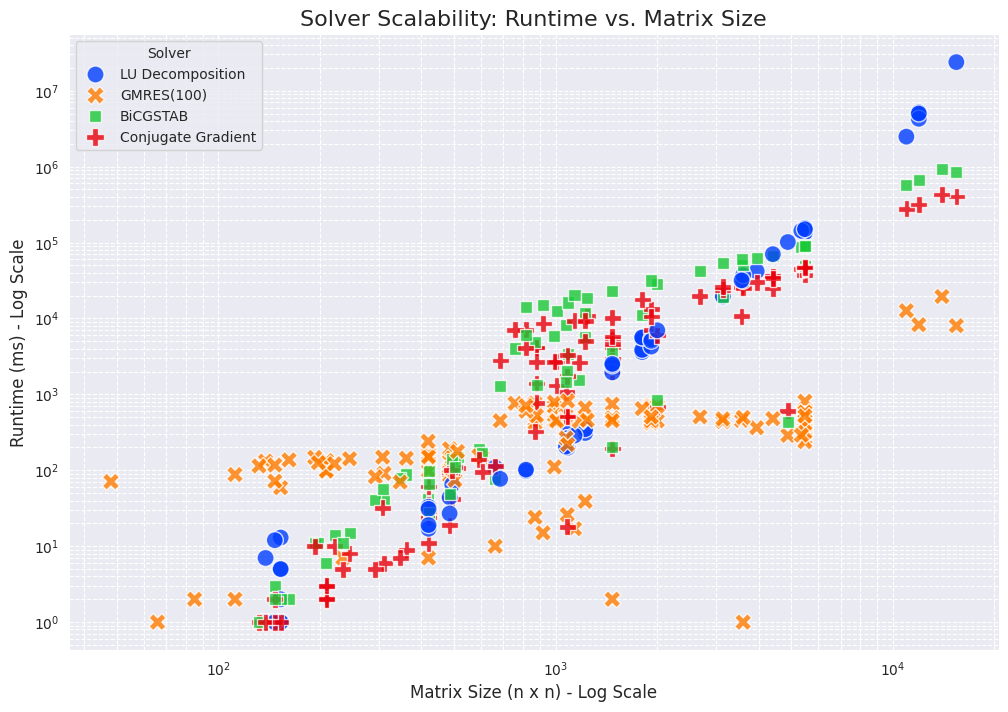

In [58]:
plot_scalability_scatter(df, "./plots/plot_scatter")

In [59]:
def plot_scalability_cpu_scatter(df: pd.DataFrame, output_dir: str):
    """
    Generates a scatter plot of runtime vs. matrix size, colored by solver.
    """
    print("📈 Generating scalability cpu scatter plot...")
    plt.figure(figsize=(12, 8))

    ax = sns.scatterplot(
        data=df,
        x='matrix_size',
        y='total_cpu_time_s',
        hue='solver_name',   # Color points by solver
        style='solver_name', # Use different marker shapes for each solver
        s=150,               # Set point size
        alpha=0.8,           # Set point transparency
        palette='bright'     # Use a color palette with good contrast
    )

    # Use a logarithmic scale for the y-axis (runtime) because LU is much slower
    ax.set_yscale('log')
    ax.set_xscale('log') # Log scale on x-axis can also help spread out matrix sizes

    ax.set_title('Solver Scalability: Cpu vs. Matrix Size', fontsize=16)
    ax.set_xlabel('Matrix Size (n x n) - Log Scale', fontsize=12)
    ax.set_ylabel('Cpu time (s) - Log Scale', fontsize=12)
    ax.grid(True, which="both", ls="--")
    ax.legend(title='Solver')

    output_path = os.path.join(output_dir, "cpu_scatter.png")
    plt.savefig(output_path, dpi=150)
    plt.show()
    plt.close()

📈 Generating scalability cpu scatter plot...


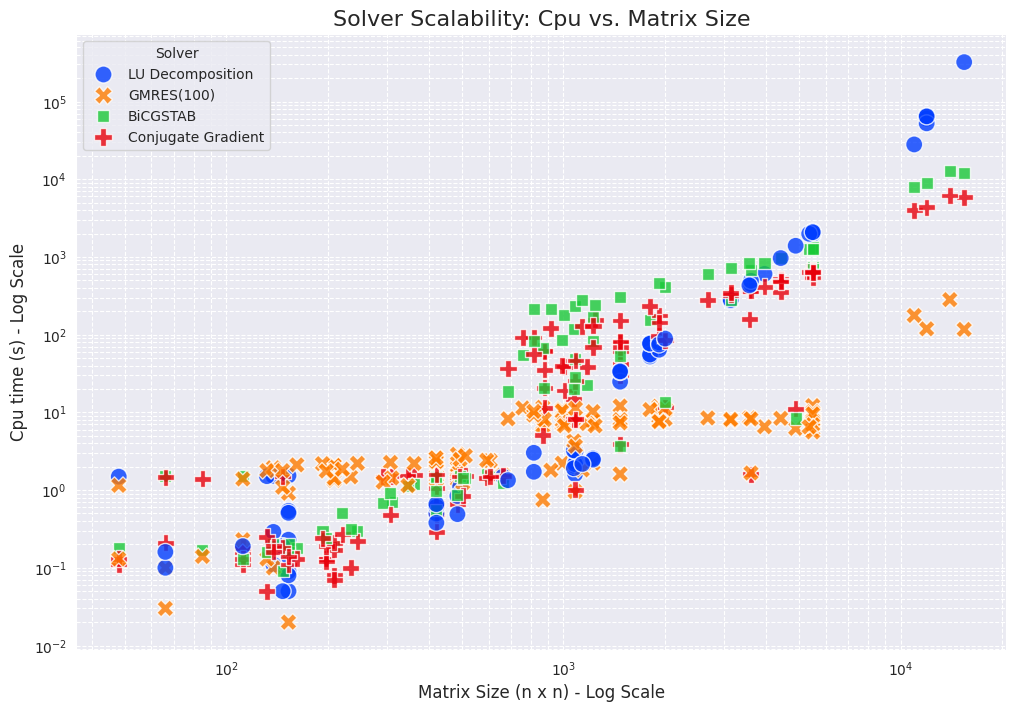

In [60]:
plot_scalability_cpu_scatter(df, "./plots/plot_scatter")

In [61]:

def plot_ram_scalability_scatter(df: pd.DataFrame, output_dir: str):
    """
    Generates a scatter plot of peak RAM usage vs. matrix size, colored by solver.
    """
    print("🧠 Generating RAM scalability scatter plot...")
    plt.figure(figsize=(12, 8))

    # Create a new column for RAM in MB for better y-axis labels
    df['max_ram_mb'] = df['max_ram_kb'] / 1024

    ax = sns.scatterplot(
        data=df,
        x='matrix_size',
        y='max_ram_mb',
        hue='solver_name',
        style='solver_name',
        s=150,
        alpha=0.8,
        palette='bright' # Use a different color palette
    )

    ax.set_yscale('log')
    ax.set_xscale('log')

    ax.set_title('Solver Peak RAM Usage vs. Matrix Size', fontsize=16)
    ax.set_xlabel('Matrix Size (n x n) - Log Scale', fontsize=12)
    ax.set_ylabel('Peak RAM (MB) - Log Scale', fontsize=12)
    ax.grid(True, which="both", ls="--")
    ax.legend(title='Solver')

    os.makedirs(output_dir, exist_ok=True)
    output_path = os.path.join(output_dir, "ram_scalability_scatter.png")

    plt.savefig(output_path, dpi=150)
    plt.show()
    plt.close()

🧠 Generating RAM scalability scatter plot...


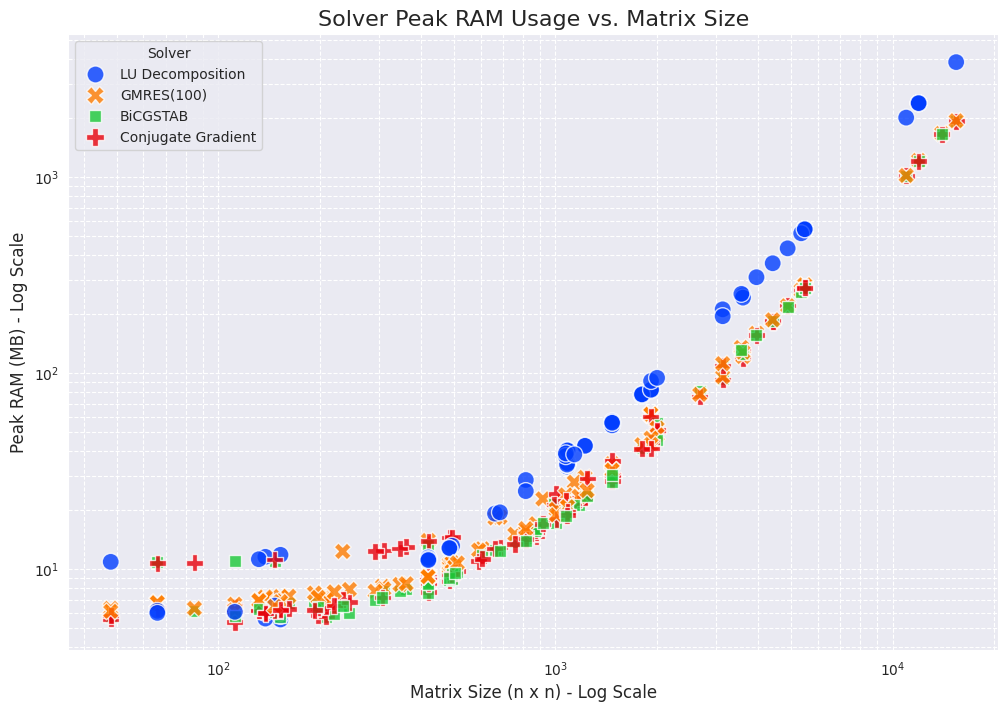

In [62]:
plot_ram_scalability_scatter(df, "./plots/plot_scatter")


In [63]:
def plot_accuracy_runtime_tradeoff(df: pd.DataFrame, output_dir: str):
    """
    Generates a scatter plot of accuracy vs. runtime, categorized by matrix size.
    """
    print("🎯 Generating Accuracy vs. Runtime trade-off plot...")
    os.makedirs(output_dir, exist_ok=True)

    def categorize_size(size):
        if size < 1000:
            return 'Small (<1k)'
        elif 1000 <= size < 5000:
            return 'Medium (1k-5k)'
        else:
            return 'Large (>=5k)'

    df['size_category'] = df['matrix_size'].apply(categorize_size)

    plt.figure(figsize=(14, 10))
    ax = sns.scatterplot(
        data=df[df['final_rel_res'] > 0],
        x='final_rel_res',
        y='time_ms',
        hue='solver_name',
        style='size_category',
        s=150,
        alpha=0.75,
        palette='deep'
    )

    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_title('Solver Performance: Accuracy vs. Runtime Trade-off by Matrix Size', fontsize=16)
    ax.set_xlabel('Final Relative Residual (Lower is Better) - Log Scale', fontsize=12)
    ax.set_ylabel('Runtime (ms) - Log Scale', fontsize=12)
    ax.grid(True, which="both", ls="--")
    ax.legend(title='Solver & Size Category')

    output_path = os.path.join(output_dir, "accuracy_runtime_tradeoff.png")
    plt.savefig(output_path, dpi=150)
    plt.show()
    plt.close()

🎯 Generating Accuracy vs. Runtime trade-off plot...


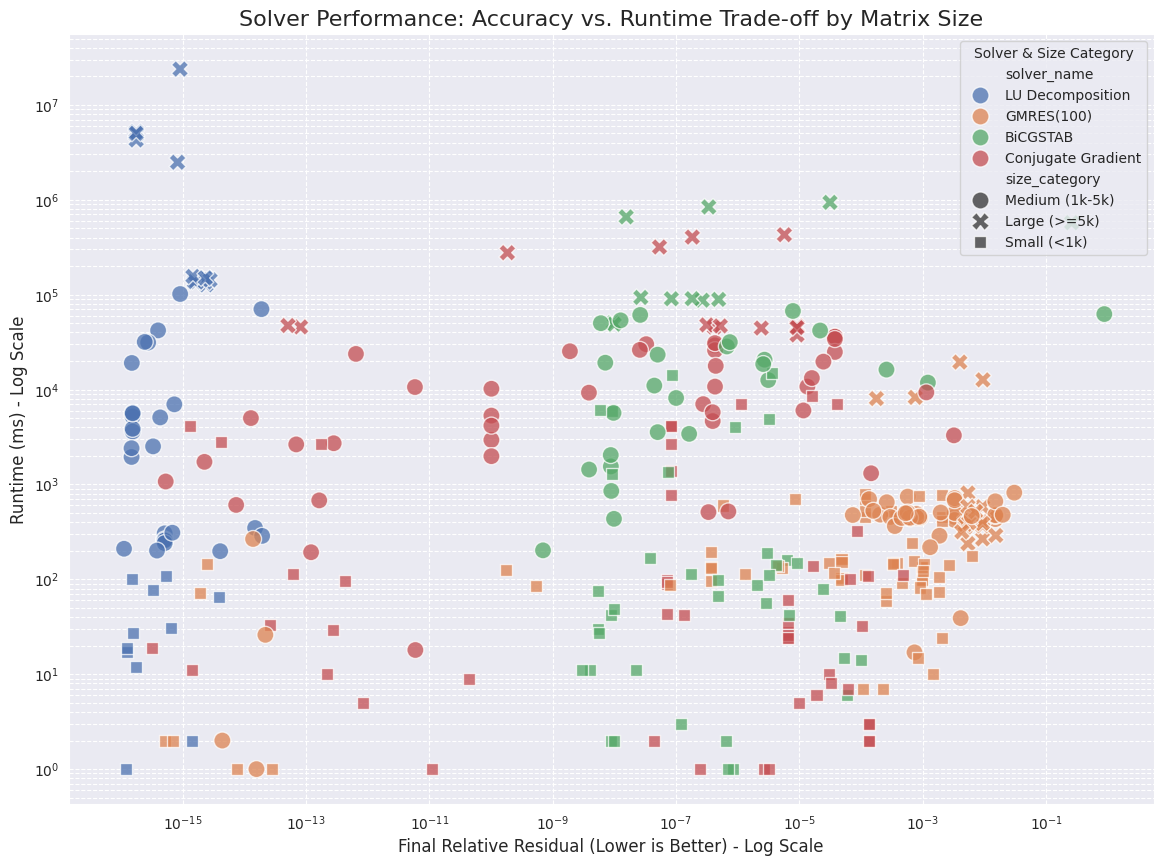

In [64]:
plot_accuracy_runtime_tradeoff(df, "./plots/plot_scatter")